Q-Learning for a Gridworld Maze: Theory
1. Problem statement

An agent must find the shortest route from a start cell to a goal cell in a grid containing walls. It isn't told the map or the rules. It learns only by trying moves and observing rewards. This is a reinforcement learning (RL) problem.

2. Formulating the maze as an MDP
Component	In the maze
State (s)	The agent's cell (row, col). An 8×8 grid gives at most 64 states.
Action (a)	UP, DOWN, LEFT, RIGHT
Transition	Deterministic. A move into a free cell succeeds. A move into a wall or the boundary leaves the agent where it is.
Reward (r)	+100 at the goal, -1 per step, -5 for hitting a wall
Terminal state	The goal cell
Discount (γ)	0.95

The Markov property holds because the current cell tells the agent everything it needs to decide. The history of how it got there doesn't matter.

3. Return and policy

The agent wants to maximize the discounted return:

Gₜ = rₜ + γ·rₜ₊₁ + γ²·rₜ₊₂ + …

A policy π(s) maps each cell to an action. The final learned policy looks like a map of arrows, one per cell.

4. Why the reward design matters
+100 at the goal gives the agent something to reach.
-1 per step makes long routes costly, so the shortest path earns the highest return. With a step reward of 0, every path that reaches the goal would look equally good.
-5 for a wall bump discourages moves that waste time.
5. Q-function and Bellman equation

Q(s,a) is the expected return from taking action a in cell s and then acting optimally. The optimal Q-function satisfies:

Q*(s,a) = E[ r + γ · maxₐ' Q*(s',a') ]

Once Q* is known, the best action in any cell is argmaxₐ Q*(s,a).

6. The Q-learning algorithm

Q-learning keeps a Q-table with one row per state and one column per action, so this maze needs 8 × 8 × 4 entries. It starts at zero. After each move (s, a, r, s'), the entry is updated:

Q(s,a) ← Q(s,a) + α · [ r + γ · maxₐ' Q(s',a') − Q(s,a) ]

α is the learning rate: how far to move toward the new estimate.
The bracket is the TD (temporal-difference) error: the target minus the current estimate.
The target is r + γ·maxQ(s',·). It is "reward now plus the best value from the next cell", so knowledge spreads backward from the goal. First the cell next to the goal learns it is good, then the cell before that, and so on.
At the goal the future term is 0, since the episode ends.
7. Off-policy learning

Q-learning is off-policy. It behaves with an exploratory policy (ε-greedy) but updates toward the greedy target (the max). It therefore learns the optimal policy even while it is still taking random actions. SARSA is the on-policy alternative: it uses the action actually taken next instead of the max.

8. Exploration vs exploitation: ε-greedy
With probability ε, take a random action (explore).
With probability 1−ε, take argmaxₐ Q(s,a) (exploit).

ε starts at 1.0 and decays to about 0.01. Early on the agent explores widely, and later it follows the route it has learned. Without exploration it can get stuck on a poor path. Without decay it never fully settles.

9. Training loop
Initialize Q(s,a) = 0 for all states and actions.
For each episode:
Place the agent at the start.
Repeat until the goal is reached or the step limit hits:
Choose a with ε-greedy.
Take it, observe r and s'.
Apply the Q-update.
Set s ← s'.
Decay ε.
After training, follow argmaxₐ Q(s,a) from the start to read off the path.
10. Convergence

For a finite MDP, Q-learning converges to Q* if every state-action pair is visited infinitely often and α decays appropriately. In practice, a small constant α and enough episodes work well for small mazes like this one, as the results show.

11. Effect of hyperparameters
Parameter	Too low	Too high
α	Slow learning	Unstable, noisy Q-values
γ	Short-sighted (γ = 0 ignores the future)	Slower convergence in some tasks
ε decay	Explores too long	Exploits too early and may miss the best path
Episodes	Q-table not converged	Wasted computation
12. Q-learning vs DQN
	Tabular Q-learning	DQN
Value storage	Table	Neural network
State space	Small, discrete	Large or continuous
Extra tricks needed	None	Replay buffer, target network
Convergence guarantee	Yes	No

The maze is small enough for a table, so it doesn't need a neural network. DQN exists for problems where the table would be too large.

13. Limitations
The table grows exponentially with the number of state variables (the "curse of dimensionality").
It cannot generalize: each cell is learned separately.
It requires many episodes to propagate values across large mazes.
It assumes the maze stays fixed. If the walls change, the learned Q-table becomes wrong.
14. Applications

Path planning for robots, game AI, and network routing all use the same idea at larger scale.

S L # R R R R D 
D # # U # # # D 
D L L D # D R D 
D # # # # D # D 
R R R R R D # D 
U # # # # D # G 
U L R D # R R U 
# # # R R U # U 


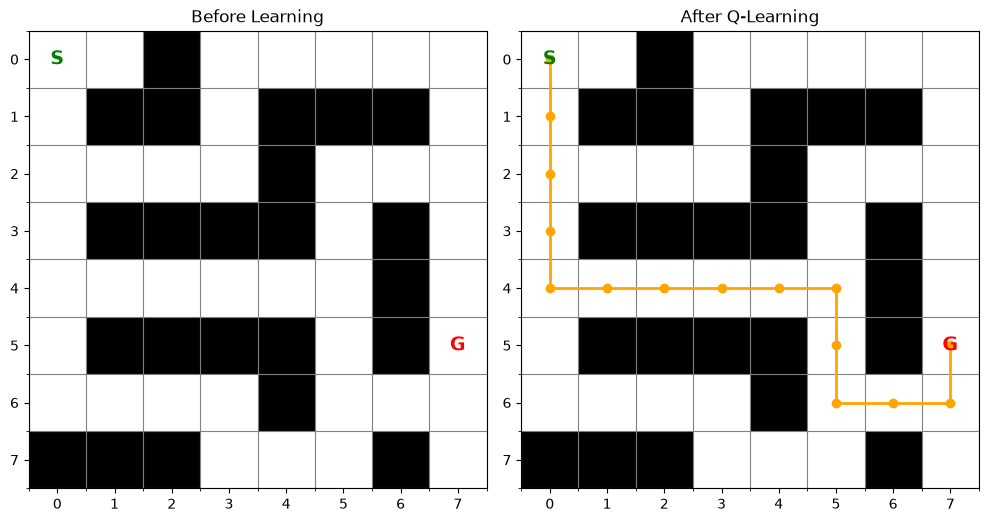

In [1]:
import numpy as np

maze = [
    "S.#.....",
    ".##.###.",
    "....#...",
    ".####.#.",
    "......#.",
    ".####.#G",
    "....#...",
    "###...#."
]

Q = np.zeros((8, 8, 4))
actions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

alpha = 0.1
gamma = 0.9
epsilon = 0.2

start = (0, 0)
goal = (5, 7)

# Training
for episode in range(3000):
    r, c = start

    for step in range(200):
        # Choose an action
        if np.random.random() < epsilon:
            a = np.random.randint(4)
        else:
            a = np.argmax(Q[r, c])

        nr = r + actions[a][0]
        nc = c + actions[a][1]

        # Check wall or boundary
        if (nr < 0 or nr >= 8 or nc < 0 or nc >= 8
                or maze[nr][nc] == '#'):
            reward = -5
            nr, nc = r, c
        elif (nr, nc) == goal:
            reward = 100
        else:
            reward = -1

        # Q-learning update
        Q[r, c, a] += alpha * (
            reward + gamma * (0 if (nr, nc) == goal
                              else np.max(Q[nr, nc]))
            - Q[r, c, a]
        )

        r, c = nr, nc

        if (r, c) == goal:
            break

# Display best action in every cell
arrows = ['U', 'D', 'L', 'R']

for r in range(8):
    for c in range(8):
        if maze[r][c] == '#':
            print('#', end=' ')
        elif (r, c) == start:
            print('S', end=' ')
        elif (r, c) == goal:
            print('G', end=' ')
        else:
            print(arrows[np.argmax(Q[r, c])], end=' ')
    print()
import matplotlib.pyplot as plt
import numpy as np

# Find the learned path
r, c = start
path = [(r, c)]

for _ in range(100):
    a = np.argmax(Q[r, c])
    r += actions[a][0]
    c += actions[a][1]

    # Stop if the move hits a wall or boundary
    if (r < 0 or r >= 8 or c < 0 or c >= 8
            or maze[r][c] == '#'):
        break

    path.append((r, c))

    if (r, c) == goal:
        break

# Convert maze into numbers for plotting
grid = np.zeros((8, 8))

for r in range(8):
    for c in range(8):
        if maze[r][c] == '#':
            grid[r, c] = 1

# Plot before and after
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

for i in range(2):
    ax[i].imshow(grid, cmap='Greys', vmin=0, vmax=1)
    ax[i].set_xticks(range(8))
    ax[i].set_yticks(range(8))
    ax[i].set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax[i].set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax[i].grid(which='minor', color='gray')
    ax[i].set_xlim(-0.5, 7.5)
    ax[i].set_ylim(7.5, -0.5)

    ax[i].text(0, 0, 'S', ha='center', va='center',
               color='green', fontsize=14, fontweight='bold')
    ax[i].text(7, 5, 'G', ha='center', va='center',
               color='red', fontsize=14, fontweight='bold')

ax[0].set_title("Before Learning")

# Draw learned path
ys, xs = zip(*path)
ax[1].plot(xs, ys, 'o-', color='orange', linewidth=2)

ax[1].set_title("After Q-Learning")

plt.tight_layout()
plt.show()
